# Машинное обучение, ФКН ВШЭ

## Практическое задание 2. Exploratory Data Analysis и линейная регрессия

### Общая информация
Дата выдачи: 12.10.2024

Мягкий дедлайн: 23:59MSK 27.10.2024

Жесткий дедлайн: 23:59MSK 31.10.2024

### О задании
В этом задании мы попытаемся научиться анализировать данные и выделять из них полезные признаки. Мы также научимся пользоваться `sklearn`, а заодно привыкнем к основным понятиям машинного обучения.

### Оценивание и штрафы
Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). Максимально допустимая оценка за работу — 10 баллов. Проверяющий имеет право снизить оценку за неэффективную реализацию или неопрятные графики.

**Обратите внимание**, что в каждом разделе домашнего задания есть оцениваниемые задачи и есть вопросы. Вопросы дополняют задачи и направлены на то, чтобы проинтерпретировать или обосновать происходящее. Код без интерпретации не имеет смысла, поэтому отвечать на вопросы обязательно — за отсутствие ответов мы будем снижать баллы за задачи. Если вы ответите на вопросы, но не напишете корректный код к соответствующим оцениваемым задачам, то баллы за такое выставлены не будут.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

### Формат сдачи
Задания сдаются через систему Anytask. Инвайт можно найти на странице курса. Присылать необходимо ноутбук с выполненным заданием. Сам ноутбук называйте в формате homework-practice-02-linregr-Username.ipynb, где Username — ваша фамилия.

Для удобства проверки самостоятельно посчитайте свою максимальную оценку (исходя из набора решенных задач) и укажите ниже.

Оценка: xx.

В этом ноутбуке используется библиотека `folium` для визуализации карт. Она работает в google colab!

In [ ]:
!pip install folium

In [ ]:
import folium

m = folium.Map(location=(50.97178, 9.79418), zoom_start=15)

m

Если вы всё сделали правильно, то выше должна открыться карта

### 📌 **Памятка по дз2**

Обрабатывать данные можно любым способом (`polars`, `pandas`, `pyspark`, ...), который вам нравится и запускается в ноутбуке, и любой библиотекой для визуализации (`matplotlib`, `seaborn`, `plotly`, ...). Пользуйтесь на здоровье, но!

> Учтите, что `polars` всё ещё молодой и не все библиотеки его поддерживают. `sklearn` во многом уже работает, но на всякий случай не стесняйтесь пользоваться методами `pl.DataFrame.to_pandas()` или `pl.DataFrame.to_numpy()`    

> Впрочем, `pandas` тоже не лишён проблем. `sklearn` принимает `pd.DataFrame` почти везде, проблемы очень редки, но если вдруг возникнет какая-то беда с шейпами, или ещё какой-нибудь казус, а вы уверены, что всё правильно, пользуйтесь `pd.DataFrame.to_numpy()`. Это не всегда решает проблему, но часто помогает понять, что на самом деле не так. При желании можно передавать и `Iterable`, и sparse-матрицы

> Графики должны быть понятные, читаемые и пр. Консультируйтесь с памяткой из дз1 в задании на график

> Для воспроизводимости результатов не забывайте пользоваться `np.random.seed(...)`, при необходимости чистите мусор `gc.collect()`, лучше в каждой ячейке

> Все результаты должны быть получены в ноутбуке. На каждый **Вопрос** долен быть дан **Ответ** (письменно (в Markdown например) или кодом)

In [ ]:
import numpy as np

import pandas as pd  # your favorite data package
import matplotlib.pyplot as plt  # your favorite visualization package

## Часть 0. Подготовка (1 балл)

**Задание 1 (1 балл)**. Мы будем работать с данными из соревнования [New York City Taxi Trip Duration](https://www.kaggle.com/c/nyc-taxi-trip-duration/overview), в котором нужно было предсказать длительность поездки на такси. Скачайте обучающую выборку из этого соревнования и загрузите ее:

In [ ]:
#╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
df = pd.read_csv('train.zip')

In [ ]:
df['trip_duration'].values

array([ 455,  663, 2124, ...,  764,  373,  198])

In [ ]:
df.head(5)

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


Обратите внимание на колонки `pickup_datetime` и `dropoff_datetime`. `dropoff_datetime` был добавлена организаторами только в обучающую выборку, то есть использовать эту колонку нельзя, давайте удалим ее. В `pickup_datetime` записаны дата и время начала поездки. Чтобы с ней было удобно работать, давайте преобразуем даты в `datetime`-объекты

In [ ]:
#╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
dropoff_datetime = df['dropoff_datetime']
df = df.drop('dropoff_datetime', axis=1)
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])

В колонке `trip_duration` записано целевое значение, которое мы хотим предсказывать. Давайте посмотрим на распределение таргета в обучающей выборке. Для этого нарисуйте его гистограмму:

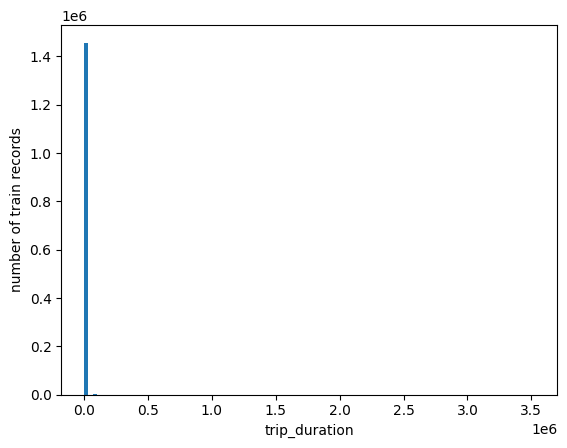

In [ ]:
#╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
plt.hist(df['trip_duration'].values, bins=100)
plt.xlabel('trip_duration')
plt.ylabel('number of train records')
plt.show()

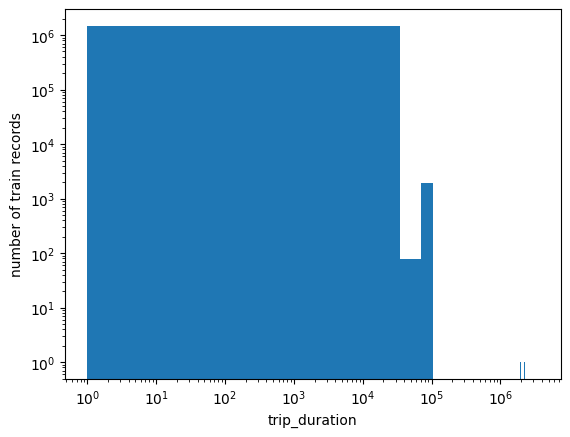

In [ ]:
plt.hist(df['trip_duration'].values, bins=100)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('trip_duration')
plt.ylabel('number of train records')
plt.show()

**Вопрос**: Что можно сказать о целевой переменной по гистограмме её значений?

В соревновании в качестве метрики качества использовалось RMSLE:
$$\text{RMSLE}(X, y, a) = \sqrt{\frac{1}{\ell}\sum_{i=1}^{\ell} \big(\log{(y_i + 1)} - \log{(a(x_i) + 1)}\big)^2}$$

**Вопрос**: Как вы думаете, почему авторы соревнования выбрали именно RMSLE, а не RMSE?

На семинаре мы рассматривали несколько моделей линейной регрессии в `sklearn`, но каждая из них оптимизировала среднеквадратичную ошибку (MSE), а не RMSLE. Давайте проделаем следующий трюк: будем предсказывать не целевую переменную, а ее *логарифм*. Обозначим $\hat{y}_i = \log{(y_i + 1)}$ — модифицированный таргет, а $\hat{a}(x_i)$ — предсказание модели, которая обучалась на $\hat{y}_i$, то есть логарифм таргета. Чтобы предсказать исходное значение, мы можем просто взять экспоненту от нашего предсказания: $a(x_i) = \exp(\hat{a}(x_i)) - 1$.

**Вопрос**: Покажите, что оптимизация RMSLE для модели $a$ эквивалентна оптимизации MSE для модели $\hat{a}$.

**Доказательство**: ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ

Итак, мы смогли свести задачу оптимизации RMSLE к задаче оптимизации MSE, которую мы умеем решать! Кроме того, у логарифмирования таргета есть еще одно полезное свойство. Чтобы его увидеть, добавьте к нашей выборке колонку `log_trip_duration` (воспользуйтесь `np.log1p`) и нарисуйте гистограмму модифицированного таргета по обучающей выборке. Удалите колонку со старым таргетом.

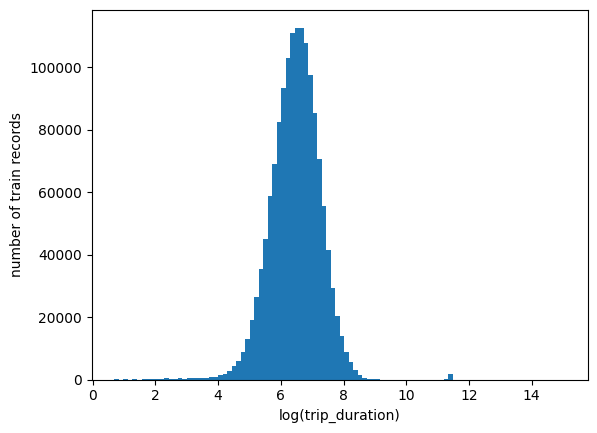

In [ ]:
#╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
df['log_trip_duration'] = np.log1p(df['trip_duration'].values)
trip_duration = df['trip_duration']
df = df.drop('trip_duration', axis=1)
plt.hist(df['log_trip_duration'].values, bins=100)
plt.xlabel('log(trip_duration)')
plt.ylabel('number of train records')
plt.show()

In [ ]:
df.head(5)

,id,vendor_id,pickup_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,log_trip_duration
0,id2875421,2,2016-03-14 17:24:55,1,-73.982155,40.767937,-73.964630,40.765602,N,6.122493
1,id2377394,1,2016-06-12 00:43:35,1,-73.980415,40.738564,-73.999481,40.731152,N,6.498282
2,id3858529,2,2016-01-19 11:35:24,1,-73.979027,40.763939,-74.005333,40.710087,N,7.661527
3,id3504673,2,2016-04-06 19:32:31,1,-74.010040,40.719971,-74.012268,40.706718,N,6.063785
4,id2181028,2,2016-03-26 13:30:55,1,-73.973053,40.793209,-73.972923,40.782520,N,6.077642


Чтобы иметь некоторую точку отсчета, давайте посчитаем значение метрики при наилучшем константном предсказании:

In [ ]:
def rmsle(log1p_y_true, log1p_y_pred):
    #╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
    return np.sqrt(np.mean((log1p_y_true - log1p_y_pred) ** 2))
    raise NotImplementedError

log_y_true = df['log_trip_duration']
log_y_pred = np.mean(log_y_true)
rmsle_best_const = rmsle(log_y_true, log_y_pred)
print(rmsle_best_const)
assert np.allclose(rmsle_best_const, 0.79575, 1e-4)

0.7957592365411509


## Часть 1. Изучаем `pickup_datetime` (2 балла)

**Задание 2 (0.25 баллов)**. Для начала давайте посмотрим, сколько всего было поездок в каждый из дней. Постройте график зависимости количества поездок от дня в году:

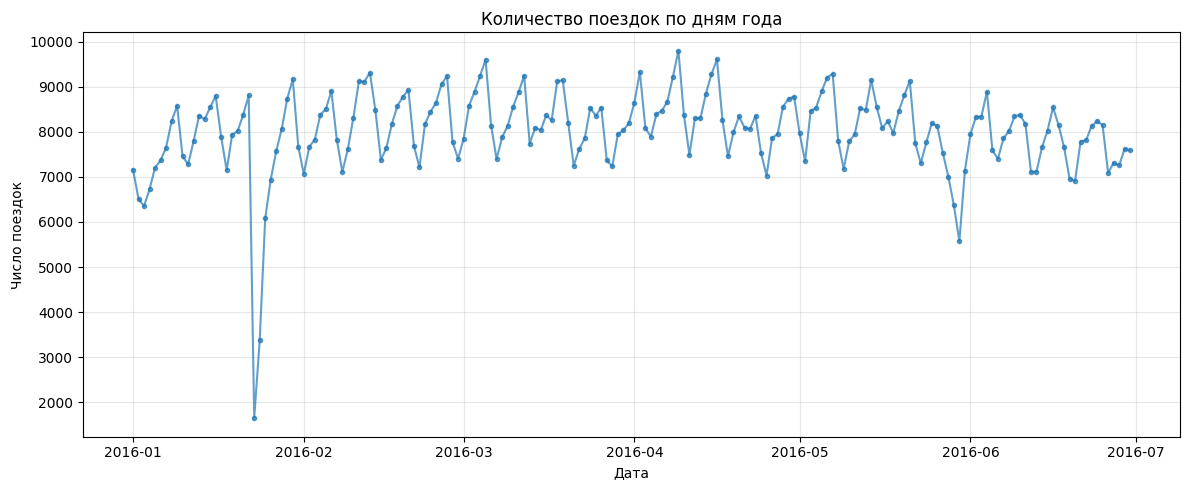

In [ ]:
#╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
plt.figure(figsize=(12, 5))

trips_per_day = df.groupby(df['pickup_datetime'].dt.date).size()
trips_per_day.index = pd.to_datetime(trips_per_day.index)

plt.plot(trips_per_day.index, trips_per_day.values, marker='.', linestyle='-', alpha=0.7)
plt.title('Количество поездок по дням года')
plt.xlabel('Дата')
plt.ylabel('Число поездок')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Вопрос**: Вы, вероятно, заметили, что на графике есть 2 периода с аномально маленькими количествами поездок. Вычислите, в какие даты происходили эти скачки вниз и найдите информацию о том, что происходило в эти дни в Нью-Йорке.

Нарисуйте графики зависимости количества поездок от дня недели и от часов в сутках:

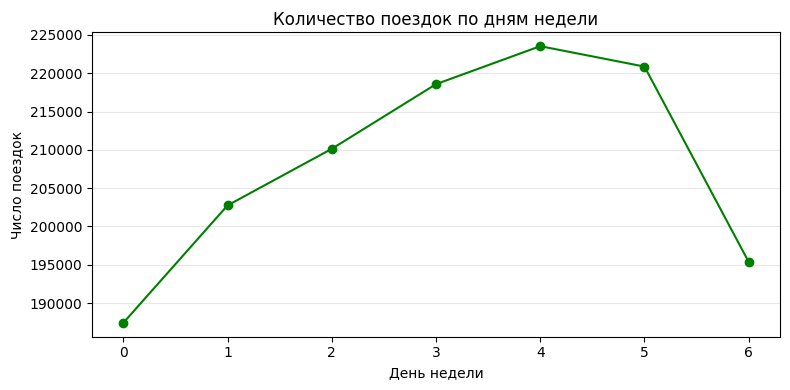

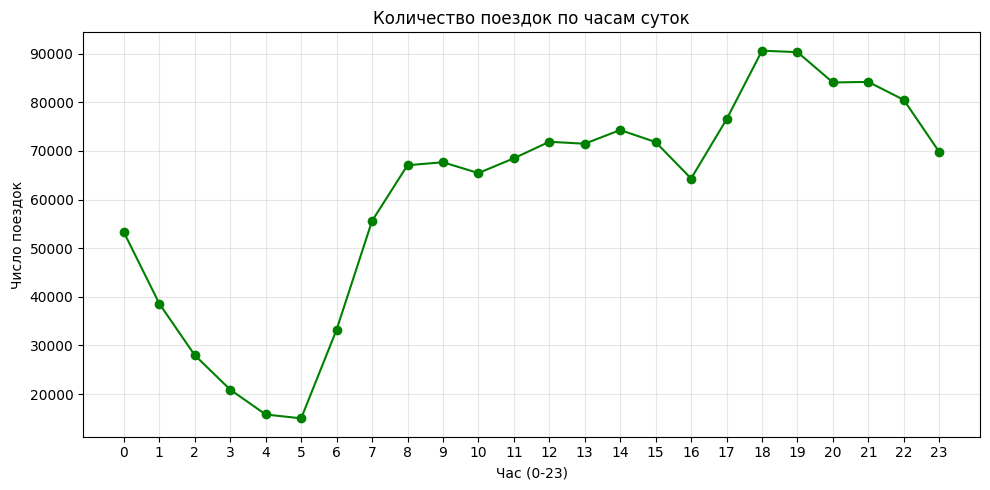

In [ ]:
#╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
df['dayofweek'] = df['pickup_datetime'].dt.dayofweek
trips_per_dayofweek = df.groupby('dayofweek').size()

plt.figure(figsize=(8, 4))
plt.plot(trips_per_dayofweek.values, marker='o', linestyle='-', color='green')
plt.title('Количество поездок по дням недели')
plt.xlabel('День недели')
plt.ylabel('Число поездок')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


df['hour'] = df['pickup_datetime'].dt.hour
trips_per_hour = df.groupby('hour').size()

plt.figure(figsize=(10, 5))
plt.plot(trips_per_hour.index, trips_per_hour.values, marker='o', linestyle='-', color='green')
plt.title('Количество поездок по часам суток')
plt.xlabel('Час (0-23)')
plt.ylabel('Число поездок')
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Задание 3 (0.5 баллов)**. Нарисуйте на одном графике зависимости количества поездок от часа в сутках для разных месяцев (разные кривые, соответствующие разным месяцам, окрашивайте в разные цвета, поищите, как это делается). Аналогично нарисуйте зависимости количества поездок от часа в сутках для разных дней недели.

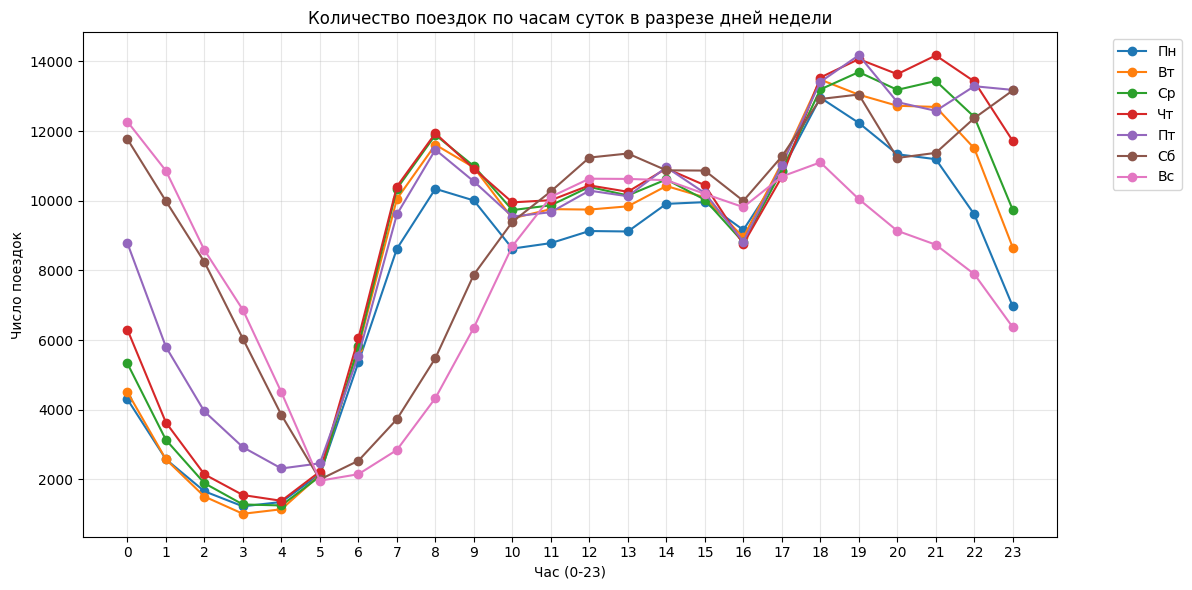

In [ ]:
#╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
# Создаём день недели (0=Пн, 6=Вс)
df['dayofweek'] = df['pickup_datetime'].dt.dayofweek

# Группировка по дню недели и часу
trips_by_hour_dow = df.groupby(['dayofweek', 'hour']).size().reset_index(name='count')

# Разворот таблицы
pivot_dow = trips_by_hour_dow.pivot(index='hour', columns='dayofweek', values='count')

# Названия дней
days_names = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']

plt.figure(figsize=(12, 6))
for dow in pivot_dow.columns:
    plt.plot(pivot_dow.index, pivot_dow[dow], marker='o', linestyle='-', label=days_names[dow])

plt.title('Количество поездок по часам суток в разрезе дней недели')
plt.xlabel('Час (0-23)')
plt.ylabel('Число поездок')
plt.xticks(range(0, 24))
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Вопрос**: Какие выводы можно сделать, основываясь на графиках выше? Выделяются ли какие-нибудь дни недели? Месяца? Время суток? С чем это связано?

**Задание 4 (0.5 баллов)**. Разбейте выборку на обучающую и тестовую в отношении 7:3 (используйте `train_test_split` из `sklearn`). По обучающей выборке нарисуйте график зависимости среднего логарифма времени поездки от дня недели. Затем сделайте то же самое, но для часа в сутках и дня в году.

Размер обучающей выборки: 1021050
Размер тестовой выборки: 437594


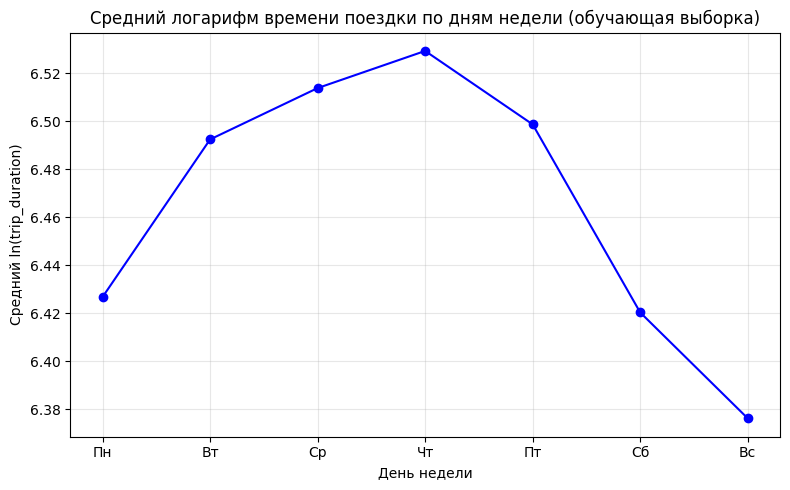

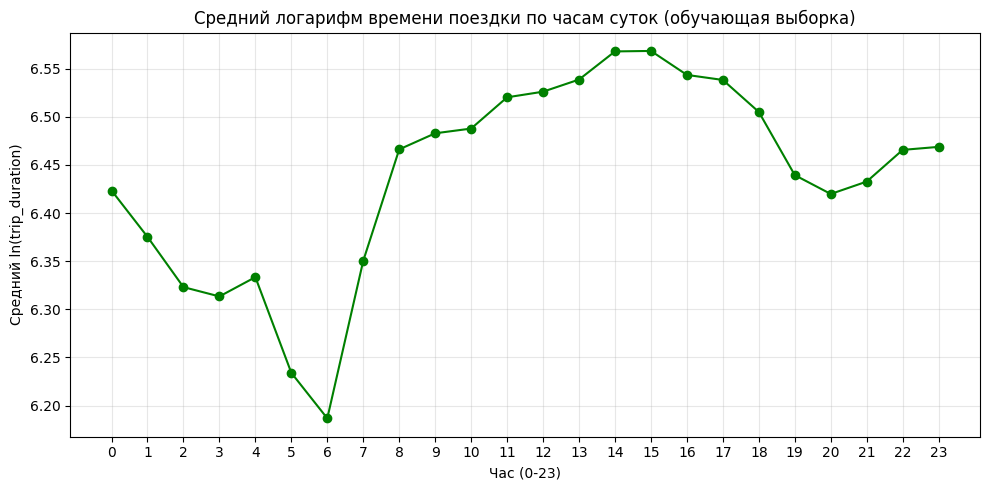

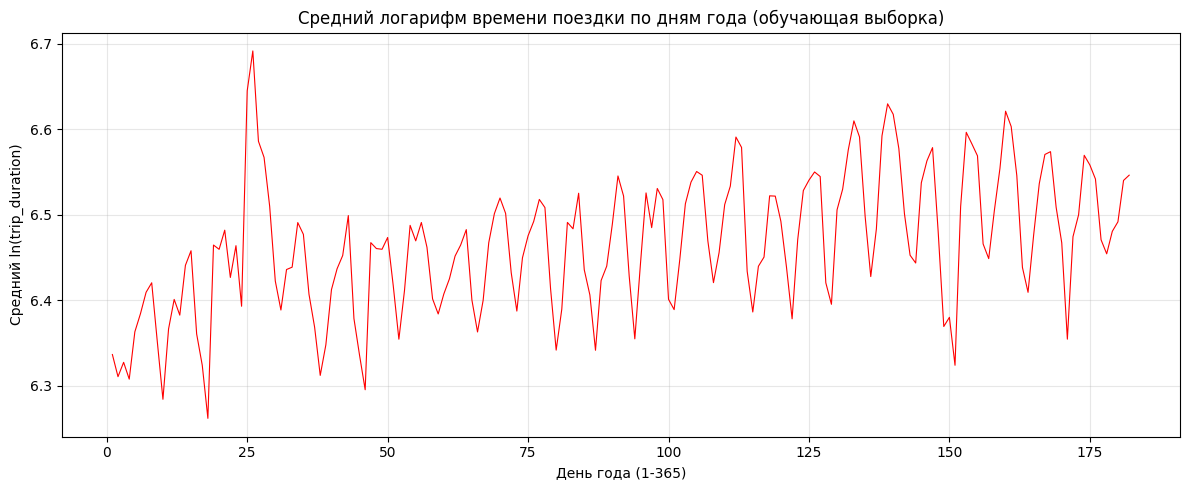

In [ ]:
#╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
from sklearn.model_selection import train_test_split

df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])
df['dayofyear'] = df['pickup_datetime'].dt.dayofyear


train_df, test_df = train_test_split(df, test_size=0.3, random_state=42)

print(f"Размер обучающей выборки: {len(train_df)}")
print(f"Размер тестовой выборки: {len(test_df)}")


# По дням недели
mean_log_by_dow = train_df.groupby('dayofweek')['log_trip_duration'].mean()
days_names = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']

plt.figure(figsize=(8, 5))
plt.plot(days_names, mean_log_by_dow.values, marker='o', linestyle='-', color='blue')
plt.title('Средний логарифм времени поездки по дням недели (обучающая выборка)')
plt.xlabel('День недели')
plt.ylabel('Средний ln(trip_duration)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#  По часам суток
mean_log_by_hour = train_df.groupby('hour')['log_trip_duration'].mean()

plt.figure(figsize=(10, 5))
plt.plot(mean_log_by_hour.index, mean_log_by_hour.values, marker='o', linestyle='-', color='green')
plt.title('Средний логарифм времени поездки по часам суток (обучающая выборка)')
plt.xlabel('Час (0-23)')
plt.ylabel('Средний ln(trip_duration)')
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# По дням года
mean_log_by_doy = train_df.groupby('dayofyear')['log_trip_duration'].mean()

plt.figure(figsize=(12, 5))
plt.plot(mean_log_by_doy.index, mean_log_by_doy.values, linestyle='-', color='red', linewidth=0.8)
plt.title('Средний логарифм времени поездки по дням года (обучающая выборка)')
plt.xlabel('День года (1-365)')
plt.ylabel('Средний ln(trip_duration)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Вопрос**: Похожи ли графики зависимости таргета от дня недели и от часа в сутках на аналогичные графики для количества поездок? Почему? Что происходит со средним таргетом в те два аномальных периода, что мы видели выше? Почему так происходит? Наблюдаете ли вы какой-нибудь тренд на графике зависимости `log_trip_duration` от номера дня в году?

Добавьте следующие признаки на основе `pickup_datetime`:
1. День недели
2. Месяц
3. Час
4. Является ли период аномальным (два бинарных признака, соответствующие двум аномальным периодам)
5. Номер дня в году

In [ ]:
df = df.drop(['dayofweek', 'hour', 'dayofyear'], axis=1)

In [ ]:
#╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
# 1. День недели (0 = понедельник, 6 = воскресенье)
df['dayofweek'] = df['pickup_datetime'].dt.dayofweek

# 2. Месяц (1–12)
df['month'] = df['pickup_datetime'].dt.month

# 3. Час (0–23)
df['hour'] = df['pickup_datetime'].dt.hour

# 4. Номер дня в году (1–365/366)
df['dayofyear'] = df['pickup_datetime'].dt.dayofyear

# 5. Бинарные признаки для двух аномальных периодов
# Пример: задаём интервалы дат (замените на свои)
anomaly_period1_start = '2016-01-23'
anomaly_period1_end   = '2016-01-24'
anomaly_period2_start = '2016-05-29'
anomaly_period2_end   = '2016-05-30'

df['is_anomaly_period1'] = ((df['pickup_datetime'] >= anomaly_period1_start) &
                            (df['pickup_datetime'] <= anomaly_period1_end)).astype(int)

df['is_anomaly_period2'] = ((df['pickup_datetime'] >= anomaly_period2_start) &
                            (df['pickup_datetime'] <= anomaly_period2_end)).astype(int)

df.head(5)

,id,vendor_id,pickup_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,log_trip_duration,dayofweek,month,hour,dayofyear,is_anomaly_period1,is_anomaly_period2
0,id2875421,2,2016-03-14 17:24:55,1,-73.982155,40.767937,-73.964630,40.765602,N,6.122493,0,3,17,74,0,0
1,id2377394,1,2016-06-12 00:43:35,1,-73.980415,40.738564,-73.999481,40.731152,N,6.498282,6,6,0,164,0,0
2,id3858529,2,2016-01-19 11:35:24,1,-73.979027,40.763939,-74.005333,40.710087,N,7.661527,1,1,11,19,0,0
3,id3504673,2,2016-04-06 19:32:31,1,-74.010040,40.719971,-74.012268,40.706718,N,6.063785,2,4,19,97,0,0
4,id2181028,2,2016-03-26 13:30:55,1,-73.973053,40.793209,-73.972923,40.782520,N,6.077642,5,3,13,86,0,0


Итак, мы уже создали некоторое количество признаков.

**Вопрос**: Какие из признаков _стоит рассматривать в этой задаче_   как категориальные, а какие - как численные? Почему?

**Задание 5 (0.75 баллов)**. Обучите `Ridge`-регрессию с параметрами по умолчанию, закодировав все категориальные признаки с помощью `OneHotEncoder`. Численные признаки отмасштабируйте с помощью `StandardScaler`. Используйте только признаки, которые мы выделили в этой части задания.

In [ ]:
df.head(5)

,id,vendor_id,pickup_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,log_trip_duration,dayofweek,month,hour,dayofyear,is_anomaly_period1,is_anomaly_period2
0,id2875421,2,2016-03-14 17:24:55,1,-73.982155,40.767937,-73.964630,40.765602,N,6.122493,0,3,17,74,0,0
1,id2377394,1,2016-06-12 00:43:35,1,-73.980415,40.738564,-73.999481,40.731152,N,6.498282,6,6,0,164,0,0
2,id3858529,2,2016-01-19 11:35:24,1,-73.979027,40.763939,-74.005333,40.710087,N,7.661527,1,1,11,19,0,0
3,id3504673,2,2016-04-06 19:32:31,1,-74.010040,40.719971,-74.012268,40.706718,N,6.063785,2,4,19,97,0,0
4,id2181028,2,2016-03-26 13:30:55,1,-73.973053,40.793209,-73.972923,40.782520,N,6.077642,5,3,13,86,0,0


In [ ]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score



X = df.drop(['log_trip_duration', 'id', 'pickup_datetime'], axis=1)
y = df['log_trip_duration']

# Категориальные признаки
categorical_features = [
    'vendor_id',
    'store_and_fwd_flag',
    'dayofweek',
    'month',
    'hour',
    'is_anomaly_period1',
    'is_anomaly_period2',
    'passenger_count'
]

# Численные признаки
numerical_features = [
    'pickup_longitude',
    'pickup_latitude',
    'dropoff_longitude',
    'dropoff_latitude',
    'dayofyear'
]

# Создаём препроцессор
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])


ridge_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Ridge())
])


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3
)


ridge_pipeline.fit(X_train, y_train)


y_pred = ridge_pipeline.predict(X_test)


rmsle1 = rmsle(y_test, y_pred)
rmsle1

np.float64(0.7747538490922625)

In [ ]:
# 1. Извлекаем обученную модель регрессии
ridge_model = ridge_pipeline.named_steps['regressor']   # или ridge_pipeline[-1]

# 2. Извлекаем препроцессор и получаем имена признаков после трансформации
preprocessor = ridge_pipeline.named_steps['preprocessor']
# Для версий sklearn >= 1.0 можно использовать get_feature_names_out()
feature_names = preprocessor.get_feature_names_out()
# feature_names будет содержать строки вида 'num__pickup_longitude', 'cat__vendor_id_X', и т.д.
# Удалим префиксы трансформаторов для краткости
clean_feature_names = [name.split('__', 1)[1] for name in feature_names]

# 3. Получаем коэффициенты и свободный член
coefs = ridge_model.coef_          # массив коэффициентов для каждого признака
intercept = ridge_model.intercept_

# 4. Собираем в удобный DataFrame
coef_df = pd.DataFrame({
    'feature': clean_feature_names,
    'coefficient': coefs
})

# Сортируем по абсолютному значению для анализа важности (опционально)
coef_df['abs_coef'] = coef_df['coefficient'].abs()
coef_df = coef_df.sort_values('abs_coef', ascending=False).drop('abs_coef', axis=1)

print("Перехват (intercept):", intercept)
print(coef_df)


Перехват (intercept): 6.170601322051911
                 feature  coefficient
50     passenger_count_0    -2.191817
54     passenger_count_4     0.433215
52     passenger_count_2     0.417446
53     passenger_count_3     0.415219
55     passenger_count_5     0.376485
56     passenger_count_6     0.374548
51     passenger_count_1     0.354534
28                hour_6    -0.265484
27                hour_5    -0.217094
57     passenger_count_7    -0.158349
37               hour_15     0.144645
36               hour_14     0.140448
38               hour_16     0.115974
35               hour_13     0.114947
25                hour_3    -0.112932
39               hour_17     0.110756
24                hour_2    -0.110683
26                hour_4    -0.107535
34               hour_12     0.104556
33               hour_11     0.099112
1        pickup_latitude    -0.097672
0       pickup_longitude     0.096689
15           dayofweek_6    -0.092369
29                hour_7    -0.085561
47  is_ano

## Часть 2. Изучаем координаты (3 балла)
Мы уже очень хорошо изучили данные о времени начала поездки, давайте теперь посмотрим на информацию о координатах начала и конца поездки. Мы подготовили для вас функцию, которая на карте рисует точки начала или конца поездки. Примеры ее вызова вы найдете ниже. Обратите внимание, что в эту функцию мы передаем лишь небольшой кусочек данных, посколько иначе функция будет работать очень долго

In [ ]:
from typing import Iterable

def show_circles_on_map(
    latitude_values: Iterable[float],
    longitude_values: Iterable[float],
    color: str = "blue",
) -> folium.Map:
    """
    The function draws map with circles on it.
    The center of the map is the mean of coordinates passed in data.
    Works best on samples of size < 10k, too costly otherwise

    latitude_values: sample latitude values of a dataframe
    longitude_column: sample longitude values of a dataframe
    color: the color of circles to be drawn
    """

    location = (np.mean(latitude_values), np.mean(longitude_values))
    m = folium.Map(location=location)

    for lat, lon in zip(latitude_values, longitude_values):
        folium.Circle(
            radius=100,
            location=(lat, lon),
            color=color,
            fill_color=color,
            fill=True
        ).add_to(m)

    return m

Напишите функция, которая вернет значения колонок `pickup_latitude`, `pickup_longitude` на каком-нибудь разумном кусочке датафрейма, например, `df.sample(1000)` и покажите на карте, используя `show_circles_on_map`

In [ ]:
#╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
your_lat_values = df['pickup_latitude'].sample(1000).values
your_lon_values = df['pickup_longitude'].sample(1000).values
show_circles_on_map([40.8265202331543], [-73.92578765869139], color="midnightblue")

**Вопрос**: Какие пункты (или скопления точек, в количестве 2-3), по вашему мнению, выделяются на карте от основной массы и могут быть полезны для нашей задачи? Почему вы их выбрали? В чём особенность этих скоплений точек для нашей задачи?

**Задание 6 (0.75 балл)**. Как мы все прекрасно помним, $t = s / v_{\text{ср}}$, поэтому очевидно, что самым сильным признаком будет расстояние, которое необходимо проехать. Мы не можем посчитать точное расстояние, которое необходимо преодолеть такси, но мы можем его оценить, посчитав кратчайшее расстояние между точками начала и конца поездки. Чтобы корректно посчитать расстояние между двумя точками на Земле, можно использовать функцию `haversine`. Также можно воспользоваться кодом с первого семинара. Посчитайте кратчайшее расстояние для объектов и запишите его в колонку `haversine`:

In [ ]:
#╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
def haversine(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = map(np.radians, (lat1, lng1, lat2, lng2))
    AVG_EARTH_RADIUS = 6371  # in km
    lat = lat2 - lat1
    lng = lng2 - lng1
    d = np.sin(lat * 0.5) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(lng * 0.5) ** 2
    h = 2 * AVG_EARTH_RADIUS * np.arcsin(np.sqrt(d))
    return h

df['haversine'] = haversine(
    df['pickup_latitude'], df['pickup_longitude'],
    df['dropoff_latitude'], df['dropoff_longitude']
)

Так как мы предсказываем логарифм времени поездки и хотим, чтобы наши признаки были линейно зависимы с этой целевой переменной, нам нужно логарифмировать расстояние: $\log t = \log s - \log{v_{\text{ср}}}$. Запишите логарифм `haversine` в отдельную колонку `log_haversine`:

In [ ]:
#╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
haversine_fixed = df['haversine'].clip(lower=0.001)
df['log_haversine'] = np.log(haversine_fixed)

Посчитайте корреляцию и убедитесь, что логарифм расстояния лучше отражает таргет, чем просто расстояние:

In [ ]:
#╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
corr_hav = df['haversine'].corr(df['log_trip_duration'])
corr_log_hav = df['log_haversine'].corr(df['log_trip_duration'])

print(f"Корреляция haversine → log_trip_duration: {corr_hav:.4f}")
print(f"Корреляция log_haversine → log_trip_duration: {corr_log_hav:.4f}")

Корреляция haversine → log_trip_duration: 0.5736
Корреляция log_haversine → log_trip_duration: 0.7223


**Задание 7 (0.75 балла)**. Давайте изучим среднюю скорость движения такси. Посчитайте среднюю скорость для каждого объекта обучающей выборки, разделив `haversine` на `trip_duration`, и нарисуйте гистограмму ее распределения

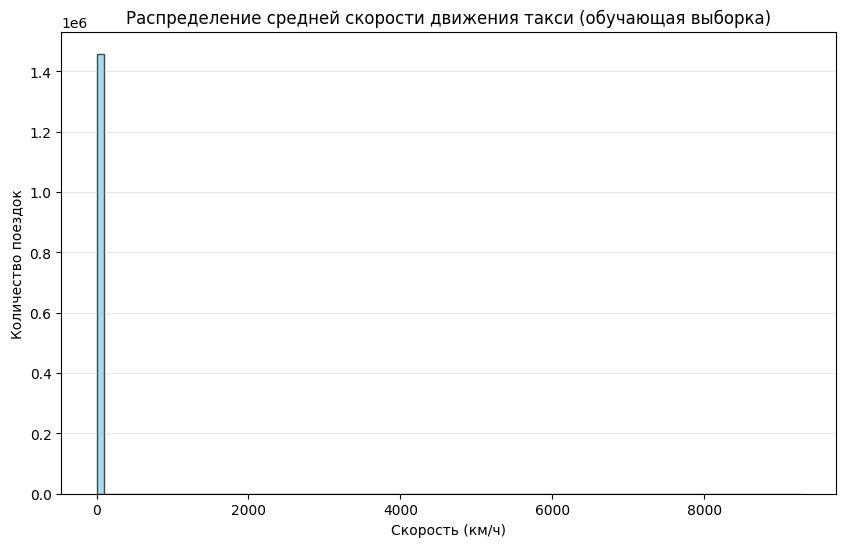

In [ ]:
#╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
# Скорость в км/ч
df['speed_kmh'] = df['haversine'] / (trip_duration / 3600)

plt.figure(figsize=(10, 6))
plt.hist(df['speed_kmh'], bins=100, edgecolor='black', alpha=0.7, color='skyblue')
plt.title('Распределение средней скорости движения такси (обучающая выборка)')
plt.xlabel('Скорость (км/ч)')
plt.ylabel('Количество поездок')
plt.grid(axis='y', alpha=0.3)
plt.show()

Как можно видеть по гистограмме, для некоторых объектов у нас получились очень больше значения скоростей. Нарисуйте гистограмму по объектам, для которых значение скорости получилось разумным (например, можно не включать рассмотрение объекты, где скорость больше некоторой квантили):

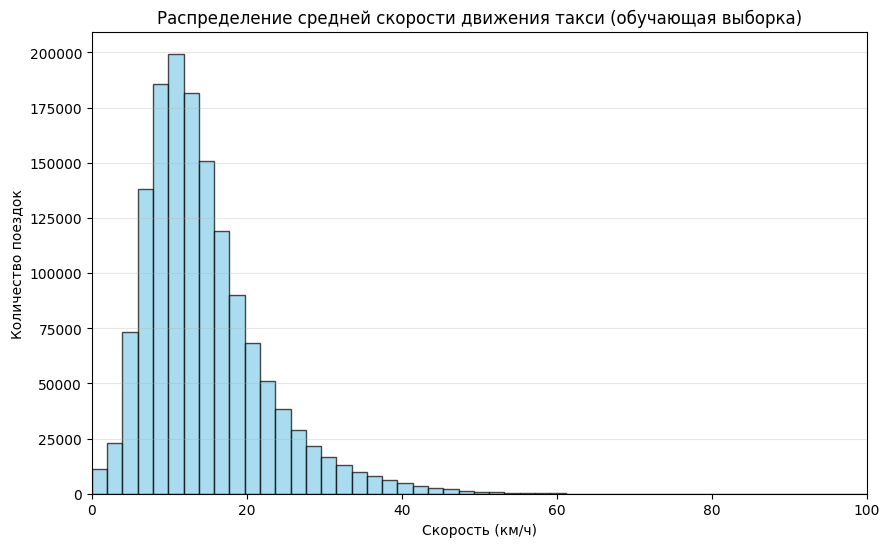

In [ ]:
#╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
mask = (trip_duration > 0) & (df['haversine'] > 0) & (df['speed_kmh'] <= 200) & (df['speed_kmh'] >= 0)
speed_clean = df.loc[mask, 'speed_kmh']

plt.figure(figsize=(10, 6))
plt.hist(speed_clean, bins=100, edgecolor='black', alpha=0.7, color='skyblue')
plt.title('Распределение средней скорости движения такси (обучающая выборка)')
plt.xlabel('Скорость (км/ч)')
plt.ylabel('Количество поездок')
plt.grid(axis='y', alpha=0.3)
plt.xlim(0, 100)
plt.show()

Для каждой пары (день недели, час суток) посчитайте медиану скоростей. Нарисуйте Heatmap-график, где по осям будут дни недели и часы, а в качестве значения функции - медиана скорости

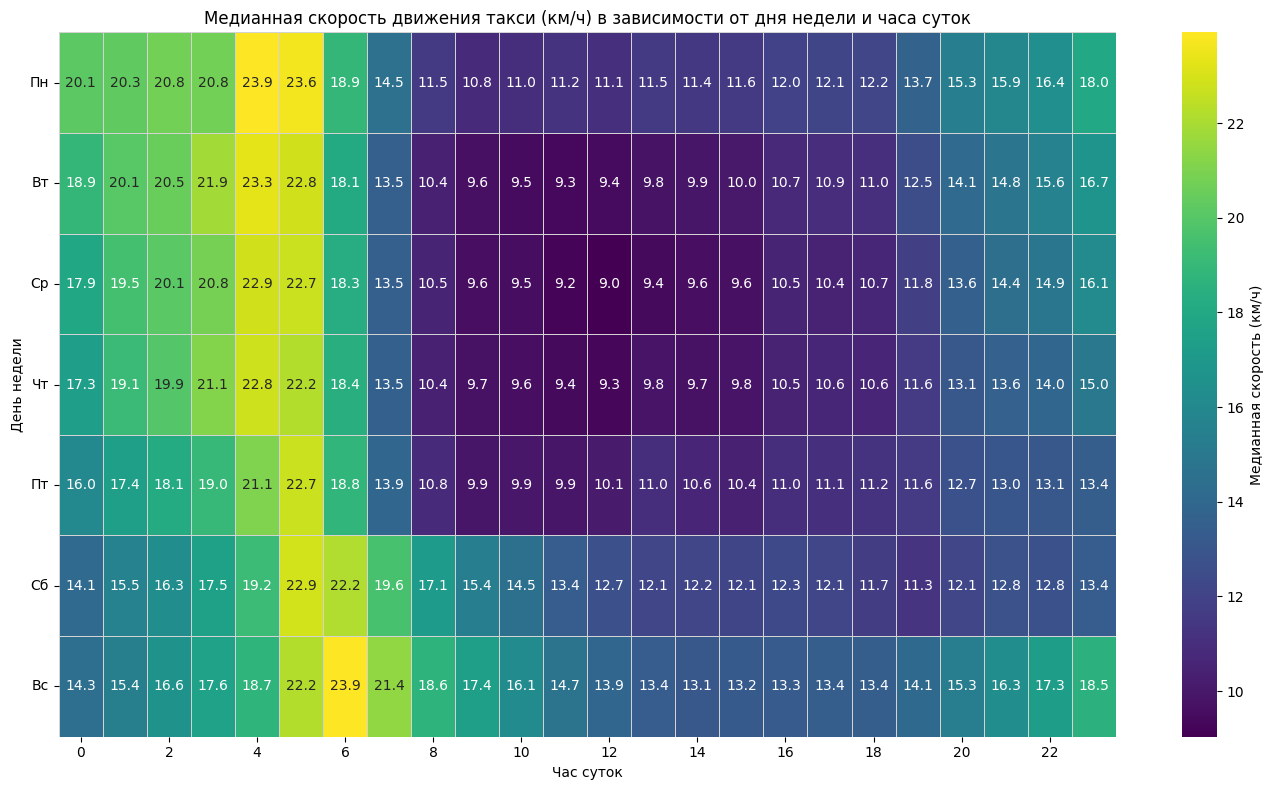

In [ ]:
#╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
import seaborn as sns
mask = (df['speed_kmh'] > 0) & (df['speed_kmh'] <= 200)
filtered = df[mask]
speed_median = filtered.groupby(['dayofweek', 'hour'])['speed_kmh'].median().unstack()

days_labels = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']

plt.figure(figsize=(14, 8))
sns.heatmap(speed_median,
            annot=True, fmt='.1f',
            cmap='viridis',
            cbar_kws={'label': 'Медианная скорость (км/ч)'},
            linewidths=0.5, linecolor='lightgray')

plt.title('Медианная скорость движения такси (км/ч) в зависимости от дня недели и часа суток')
plt.xlabel('Час суток')
plt.ylabel('День недели')
plt.yticks(ticks=np.arange(7) + 0.5, labels=days_labels, rotation=0)
plt.xticks(ticks=np.arange(0, 24, 2) + 0.5, labels=range(0, 24, 2))
plt.tight_layout()
plt.show()
df = df.drop('speed_kmh', axis=1)

Не забудьте удалить колонку со значением скорости из данных!

**Вопрос**: Почему значение скорости нельзя использовать во время обучения?

In [ ]:
#╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ

**Вопрос**: Посмотрите внимательно на график и скажите, в какие моменты времени скорость минимальна; максимальна.

Создайте признаки "поездка совершается в период пробок" и "поездка совершается в период свободных дорог" (естественно, они не должен зависеть от скорости!):

In [ ]:
#╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
df['is_rush_hour'] = (
    (df['dayofweek'] < 5) &
    ((df['hour'] >= 8) & (df['hour'] <= 18))
).astype(int)

df['is_free_road'] = ((df['hour'] >= 0) & (df['hour'] <= 6)).astype(int)

**Задание 8 (0.25 балла)**. Для каждого из замеченных вами выше 2-3 пунктов добавьте в выборку по два признака:
- началась ли поездка в этом пункте
- закончилась ли поездка в этом пункте

Как вы думаете, почему эти признаки могут быть полезны?

In [ ]:
#╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
from datetime import timedelta

df['dropoff_datetime'] = df['pickup_datetime'] + pd.to_timedelta(trip_duration, unit='s')

# Извлекаем час и день недели для времени окончания
df['dropoff_hour'] = df['dropoff_datetime'].dt.hour
df['dropoff_dayofweek'] = df['dropoff_datetime'].dt.dayofweek

# Признак "поездка началась в час пик" (переименуем существующий)
df['rush_hour_start'] = (
    (df['dayofweek'] < 5) & (df['hour'] >= 8) & (df['hour'] <= 18)
).astype(int)

# Признак "поездка закончилась в час пик"
df['rush_hour_end'] = (
    (df['dropoff_dayofweek'] < 5) & (df['dropoff_hour'] >= 8) & (df['dropoff_hour'] <= 18)
).astype(int)

# Признак "поездка началась в свободные дороги"
df['free_road_start'] = ((df['hour'] >= 0) & (df['hour'] <= 6)).astype(int)

# Признак "поездка закончилась в свободные дороги"
df['free_road_end'] = ((df['dropoff_hour'] >= 0) & (df['dropoff_hour'] <= 6)).astype(int)

# Удаляем вспомогательные столбцы (оставляем только нужные признаки)
df.drop(columns=['dropoff_hour', 'dropoff_dayofweek'], inplace=True)
df.head(5)

,id,vendor_id,pickup_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,log_trip_duration,...,is_anomaly_period2,haversine,log_haversine,is_rush_hour,is_free_road,dropoff_datetime,rush_hour_start,rush_hour_end,free_road_start,free_road_end
0,id2875421,2,2016-03-14 17:24:55,1,-73.982155,40.767937,-73.964630,40.765602,N,6.122493,...,0,1.498521,0.404478,1,0,2016-03-14 17:32:30,1,1,0,0
1,id2377394,1,2016-06-12 00:43:35,1,-73.980415,40.738564,-73.999481,40.731152,N,6.498282,...,0,1.805507,0.590842,0,1,2016-06-12 00:54:38,0,0,1,1
2,id3858529,2,2016-01-19 11:35:24,1,-73.979027,40.763939,-74.005333,40.710087,N,7.661527,...,0,6.385098,1.853967,1,0,2016-01-19 12:10:48,1,1,0,0
3,id3504673,2,2016-04-06 19:32:31,1,-74.010040,40.719971,-74.012268,40.706718,N,6.063785,...,0,1.485498,0.395750,0,0,2016-04-06 19:39:40,0,0,0,0
4,id2181028,2,2016-03-26 13:30:55,1,-73.973053,40.793209,-73.972923,40.782520,N,6.077642,...,0,1.188588,0.172766,0,0,2016-03-26 13:38:10,0,0,0,0


Для каждого из созданных признаков нарисуйте "ящик с усами" (aka boxplot) распределения логарифма времени поездки

/tmp/ipykernel_6738/1297469072.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = plt.boxplot(data_to_plot, labels=['0', '1'], patch_artist=True)
/tmp/ipykernel_6738/1297469072.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = plt.boxplot(data_to_plot, labels=['0', '1'], patch_artist=True)
/tmp/ipykernel_6738/1297469072.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = plt.boxplot(data_to_plot, labels=['0', '1'], patch_artist=True)
/tmp/ipykernel_6738/1297469072.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support f

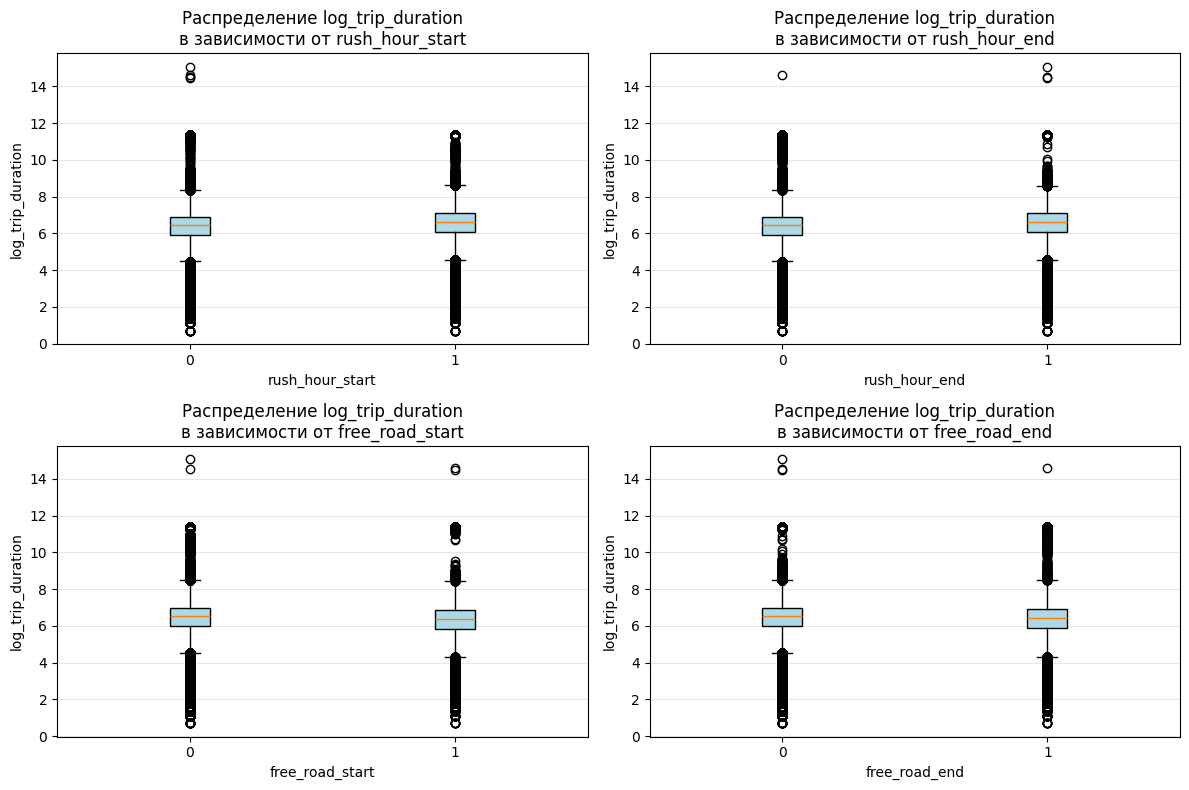

In [ ]:
#╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
features = ['rush_hour_start', 'rush_hour_end', 'free_road_start', 'free_road_end']

plt.figure(figsize=(12, 8))
for i, feature in enumerate(features, 1):
    plt.subplot(2, 2, i)

    # Собираем данные: логарифм времени для значений 0 и 1
    data_to_plot = [
        df[df[feature] == 0]['log_trip_duration'],
        df[df[feature] == 1]['log_trip_duration']
    ]

    bp = plt.boxplot(data_to_plot, labels=['0', '1'], patch_artist=True)
    # Раскрашиваем ящики
    for box in bp['boxes']:
        box.set_facecolor('lightblue')
    plt.title(f'Распределение log_trip_duration\nв зависимости от {feature}')
    plt.xlabel(feature)
    plt.ylabel('log_trip_duration')
    plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

**Вопрос**: судя по графикам, как вы думаете, хорошими ли получились эти признаки?

<img src="https://www.dropbox.com/s/xson9nukz5hba7c/map.png?raw=1" align="right" width="20%" style="margin-left: 20px; margin-bottom: 20px">

**Задание 9 (1 балл)**. Сейчас мы почти что не используем сами значения координат. На это есть несколько причин: по отдельности рассматривать широту и долготу не имеет особого смысла, стоит рассматривать их вместе. Во-вторых, понятно, что зависимость между нашим таргетом и координатами не линейная. Чтобы как-то использовать координаты, можно прибегнуть к следующему трюку: обрамим область с наибольшим количеством поездок прямоугольником (как на рисунке). Разобьем этот прямоугольник на ячейки. Каждой точке сопоставим номер ее ячейки, а тем точкам, что не попали ни в одну из ячеек, сопоставим значение -1.

Напишите трансформер, который сначала разбивает показанную на рисунке область на ячейки, а затем создает два признака: номер ячейки, в которой началась поездка, и номер ячейки, в которой закончилась поездка. Количество строк и столбцов выберите самостоятельно.

Обратите внимание, что все вычисления должны быть векторизованными, трансформер не должен модифицировать передаваемую ему выборку inplace, а все необходимые статистики (если они вдруг нужны) нужно считать только по обучающей выборке в методе `fit`:

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin


# TransformerMixin implements fit_transform for you,
# applying your fit and transform consistently

class MapGridTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, n_rows=5, n_cols=5,
                 lon_min=-74.01287841796875, lon_max=-73.92578765869139,
                 lat_min=40.71994018554688, lat_max=40.8265202331543,
                 pickup_lon_col='pickup_longitude', pickup_lat_col='pickup_latitude',
                 dropoff_lon_col='dropoff_longitude', dropoff_lat_col='dropoff_latitude'):
        # your code here
        self.n_rows = n_rows
        self.n_cols = n_cols
        self.lon_min = lon_min
        self.lon_max = lon_max
        self.lat_min = lat_min
        self.lat_max = lat_max
        self.pickup_lon_col = pickup_lon_col
        self.pickup_lat_col = pickup_lat_col
        self.dropoff_lon_col = dropoff_lon_col
        self.dropoff_lat_col = dropoff_lat_col
        pass

    # def show_map(self):
    #     # you may want to visualize cells
    #     pass

    def fit(self, X=None, y=None):
        # your code here
        self.lon_step_ = (self.lon_max - self.lon_min) / self.n_cols
        self.lat_step_ = (self.lat_max - self.lat_min) / self.n_rows
        return self

    def transform(self, X, y=None):
        # your code here

        # --- Pickup cell ---
        pickup_lon = X[self.pickup_lon_col].values
        pickup_lat = X[self.pickup_lat_col].values

        in_bounds_pickup = (pickup_lon >= self.lon_min) & (pickup_lon < self.lon_max) & \
                           (pickup_lat >= self.lat_min) & (pickup_lat < self.lat_max)

        pickup_cells = np.full_like(pickup_lon, -1, dtype=int)
        if np.any(in_bounds_pickup):
            col = ((pickup_lon[in_bounds_pickup] - self.lon_min) / self.lon_step_).astype(int)
            row = ((pickup_lat[in_bounds_pickup] - self.lat_min) / self.lat_step_).astype(int)
            col = np.clip(col, 0, self.n_cols - 1)
            row = np.clip(row, 0, self.n_rows - 1)
            pickup_cells[in_bounds_pickup] = row * self.n_cols + col

        X['pickup_cell'] = pickup_cells

        # --- Dropoff cell ---
        dropoff_lon = X[self.dropoff_lon_col].values
        dropoff_lat = X[self.dropoff_lat_col].values

        in_bounds_dropoff = (dropoff_lon >= self.lon_min) & (dropoff_lon < self.lon_max) & \
                            (dropoff_lat >= self.lat_min) & (dropoff_lat < self.lat_max)

        dropoff_cells = np.full_like(dropoff_lon, -1, dtype=int)
        if np.any(in_bounds_dropoff):
            col = ((dropoff_lon[in_bounds_dropoff] - self.lon_min) / self.lon_step_).astype(int)
            row = ((dropoff_lat[in_bounds_dropoff] - self.lat_min) / self.lat_step_).astype(int)
            col = np.clip(col, 0, self.n_cols - 1)
            row = np.clip(row, 0, self.n_rows - 1)
            dropoff_cells[in_bounds_dropoff] = row * self.n_cols + col

        X['dropoff_cell'] = dropoff_cells

        return X

**Задание 10 (0.25 балла)**. Обучите `Ridge`-регрессию со стандартными параметрами на признаках, которые мы выделили к текущему моменту. Категориальные признаки закодируйте через one-hot-кодирование, числовые признаки отмасштабируйте.

In [ ]:
#╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
X = df.drop(['log_trip_duration', 'id', 'pickup_datetime', 'dropoff_datetime'], axis=1)
y = df['log_trip_duration']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

cell_transformer = MapGridTransformer(n_rows=10, n_cols=10)
X_train = cell_transformer.fit_transform(X_train)
X_test = cell_transformer.transform(X_test)

numerical_features = [
    'dayofyear', 'dayofweek', 'month', 'hour'
]
categorical_features = [
    'is_rush_hour', 'is_free_road',
    'rush_hour_start', 'rush_hour_end', 'free_road_start', 'free_road_end',
    'is_anomaly_period1', 'is_anomaly_period2',
    'pickup_cell', 'dropoff_cell'
]
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('ridge', Ridge())
])



pipeline.fit(X_train, y_train)


y_pred = pipeline.predict(X_test)
rmsle2 = rmsle(y_test, y_pred)
print(rmsle2)
X.head(5)

0.7383028321022302


,vendor_id,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,dayofweek,month,hour,...,is_anomaly_period1,is_anomaly_period2,haversine,log_haversine,is_rush_hour,is_free_road,rush_hour_start,rush_hour_end,free_road_start,free_road_end
0,1,1,-73.982155,40.767937,-73.964630,40.765602,0,0,3,17,...,0,0,1.498521,0.404478,1,0,1,1,0,0
1,0,1,-73.980415,40.738564,-73.999481,40.731152,0,6,6,0,...,0,0,1.805507,0.590842,0,1,0,0,1,1
2,1,1,-73.979027,40.763939,-74.005333,40.710087,0,1,1,11,...,0,0,6.385098,1.853967,1,0,1,1,0,0
3,1,1,-74.010040,40.719971,-74.012268,40.706718,0,2,4,19,...,0,0,1.485498,0.395750,0,0,0,0,0,0
4,1,1,-73.973053,40.793209,-73.972923,40.782520,0,5,3,13,...,0,0,1.188588,0.172766,0,0,0,0,0,0


## Часть 3. Изучаем оставшиеся признаки (1 балл)

**Задание 11 (0.75 баллов)**. У нас осталось еще 3 признака, которые мы не исследовали: `vendor_id`, `passenger_count` и `store_and_fwd_flag`.

**Вопрос**: Подумайте, почему каждый из этих признаков может быть потенциально полезным.

Посчитайте, сколько есть уникальных значений у каждого из этих признаков:

In [ ]:
#╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
print(df['vendor_id'].nunique())
print(df['passenger_count'].nunique())
print(df['store_and_fwd_flag'].unique())

2
10
['N' 'Y']


Постройте "ящики с усами" распределений логарифма времени поездки в зависимости от значений каждого из признаков

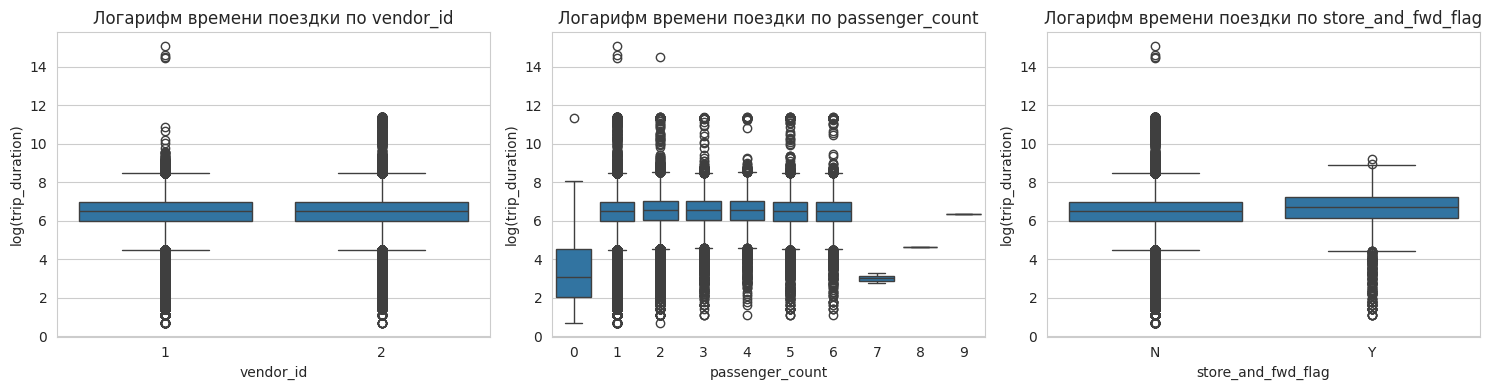

In [ ]:

# Настройка внешнего вида графиков
sns.set_style("whitegrid")
plt.figure(figsize=(15, 4))

# 1. vendor_id
plt.subplot(1, 3, 1)
sns.boxplot(data=df, x='vendor_id', y='log_trip_duration')
plt.title('Логарифм времени поездки по vendor_id')
plt.xlabel('vendor_id')
plt.ylabel('log(trip_duration)')

# 2. passenger_count
plt.subplot(1, 3, 2)
sns.boxplot(data=df, x='passenger_count', y='log_trip_duration')
plt.title('Логарифм времени поездки по passenger_count')
plt.xlabel('passenger_count')
plt.ylabel('log(trip_duration)')

# 3. store_and_fwd_flag
plt.subplot(1, 3, 3)
sns.boxplot(data=df, x='store_and_fwd_flag', y='log_trip_duration')
plt.title('Логарифм времени поездки по store_and_fwd_flag')
plt.xlabel('store_and_fwd_flag')
plt.ylabel('log(trip_duration)')

plt.tight_layout()
plt.show()

Переведите признаки `vendor_id` и `store_and_fwd_flag` в значения $\{0;1\}$

In [ ]:
#╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
df['vendor_id'] -= 1
df['store_and_fwd_flag'] = (df['store_and_fwd_flag'] == 'Y').astype(int)

**Вопрос**: Основываясь на графиках выше, как вы думаете, будут ли эти признаки сильными?

**Задание 12 (0.25 баллов)**. Проверьте свои предположения, обучив модель в том числе и на этих трех признаках. Обучайте `Ridge`-регрессию со стандартными параметрами. Категориальные признаки закодируйте one-hot-кодированием, а численные отмасштабируйте.

In [ ]:
#╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ

numerical_features = [
    'dayofyear', 'dayofweek', 'month', 'hour',
    'passenger_count'
]


categorical_features = [
    'is_rush_hour', 'is_free_road',
    'rush_hour_start', 'rush_hour_end', 'free_road_start', 'free_road_end',
    'is_anomaly_period1', 'is_anomaly_period2',
    'pickup_cell', 'dropoff_cell',
    'vendor_id',
    'store_and_fwd_flag'
]

X = df.drop(['log_trip_duration', 'id', 'pickup_datetime', 'dropoff_datetime'], axis=1)
y = df['log_trip_duration']


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)


cell_transformer = MapGridTransformer(n_rows=10, n_cols=10)
X_train = cell_transformer.fit_transform(X_train)
X_test = cell_transformer.transform(X_test)


preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('ridge', Ridge())
])


pipeline.fit(X_train, y_train)


y_pred = pipeline.predict(X_test)
rmsle_new = rmsle(y_test, y_pred)
rmsle_new

np.float64(0.7379908024085994)

Если признаки не дали какого-то ощутимого улучшения метрики, их можно выбросить из данных.

## Часть 4. Улучшаем модель (3 балла)

**Задание 13 (1 балл)**. В наших данных есть нетипичные объекты (выбросы, или outliers): с аномально маленьким времени поездки, с очень большим пройденным расстоянием или очень большими остатками регрессии. В этом задании предлагается исключить такие объекты из обучающей выборки. Для этого нарисуйте гистограммы распределения упомянутых выше величин, выберите объекты, которые можно назвать выбросами, и очистите __обучающую выборку__ от них.

Отметим, что хотя эти объекты и выглядят как выбросы, в тестовой выборке тоже скорее всего будут объекты с такими же странными значениями целевой переменной и/или признаков. Поэтому, возможно, чистка обучающей выборки приведёт к ухудшению качества на тесте. Тем не менее, всё равно лучше удалять выбросы из обучения, чтобы модель получалась более разумной и интерпретируемой.

In [ ]:
df['dropoff_datetime'] = pd.to_datetime(df['dropoff_datetime'])

In [ ]:
df.head(1)

,id,vendor_id,pickup_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,log_trip_duration,...,is_anomaly_period2,haversine,log_haversine,is_rush_hour,is_free_road,dropoff_datetime,rush_hour_start,rush_hour_end,free_road_start,free_road_end
0,id2875421,1,2016-03-14 17:24:55,1,-73.982155,40.767937,-73.96463,40.765602,0,6.122493,...,0,1.498521,0.404478,1,0,2016-03-14 17:32:30,1,1,0,0


Размер train до очистки: 1021050
Размер test: 437594


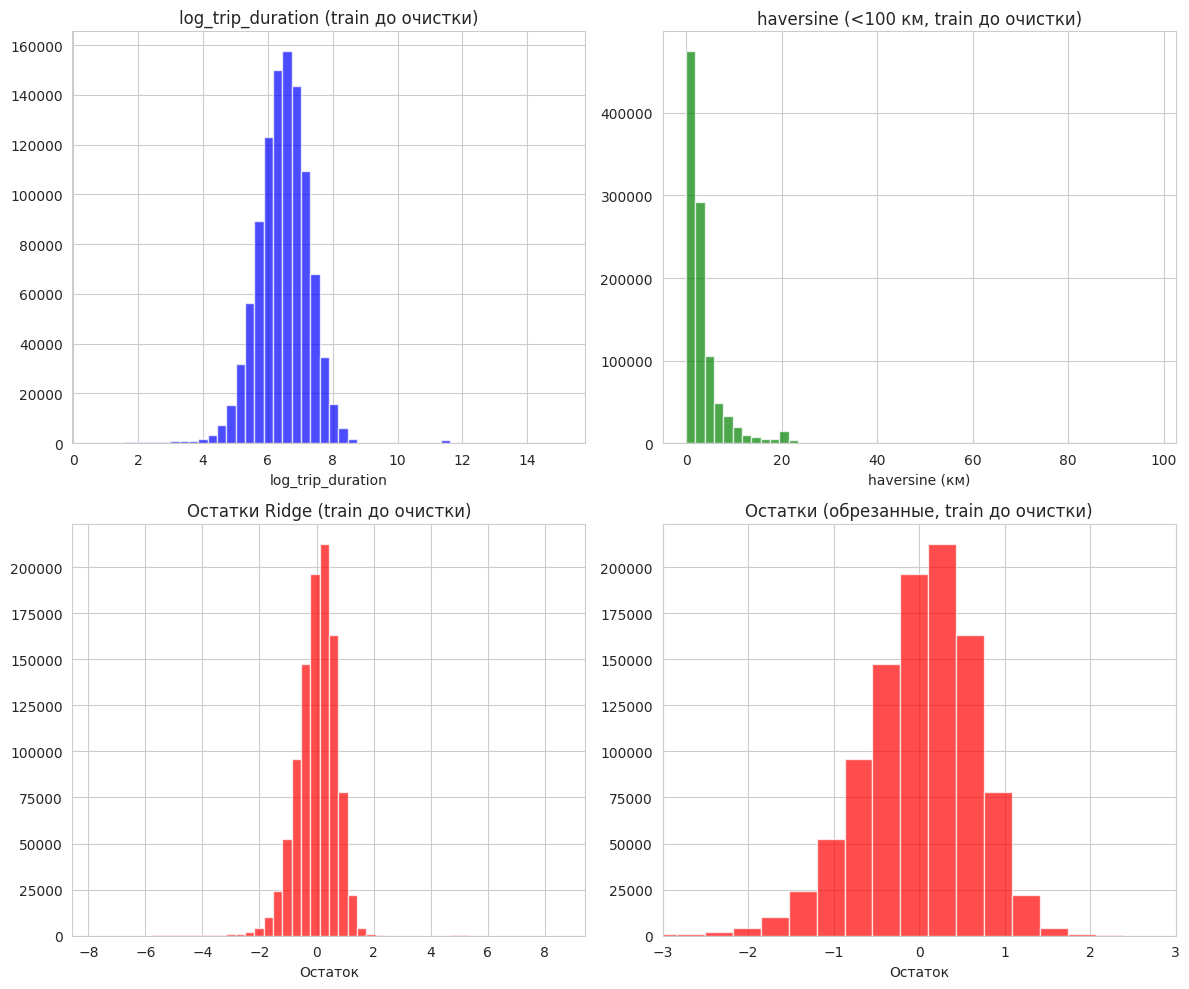

Выбросы по log_trip_duration (train): 13699
Выбросы по haversine (train): 98480
Выбросы по остаткам (train): 17989
Выбросы по haversine >= 100 (train): 13
Всего уникальных выбросов в train: 116338
Размер train до очистки: 1021050
Размер train после очистки: 904712


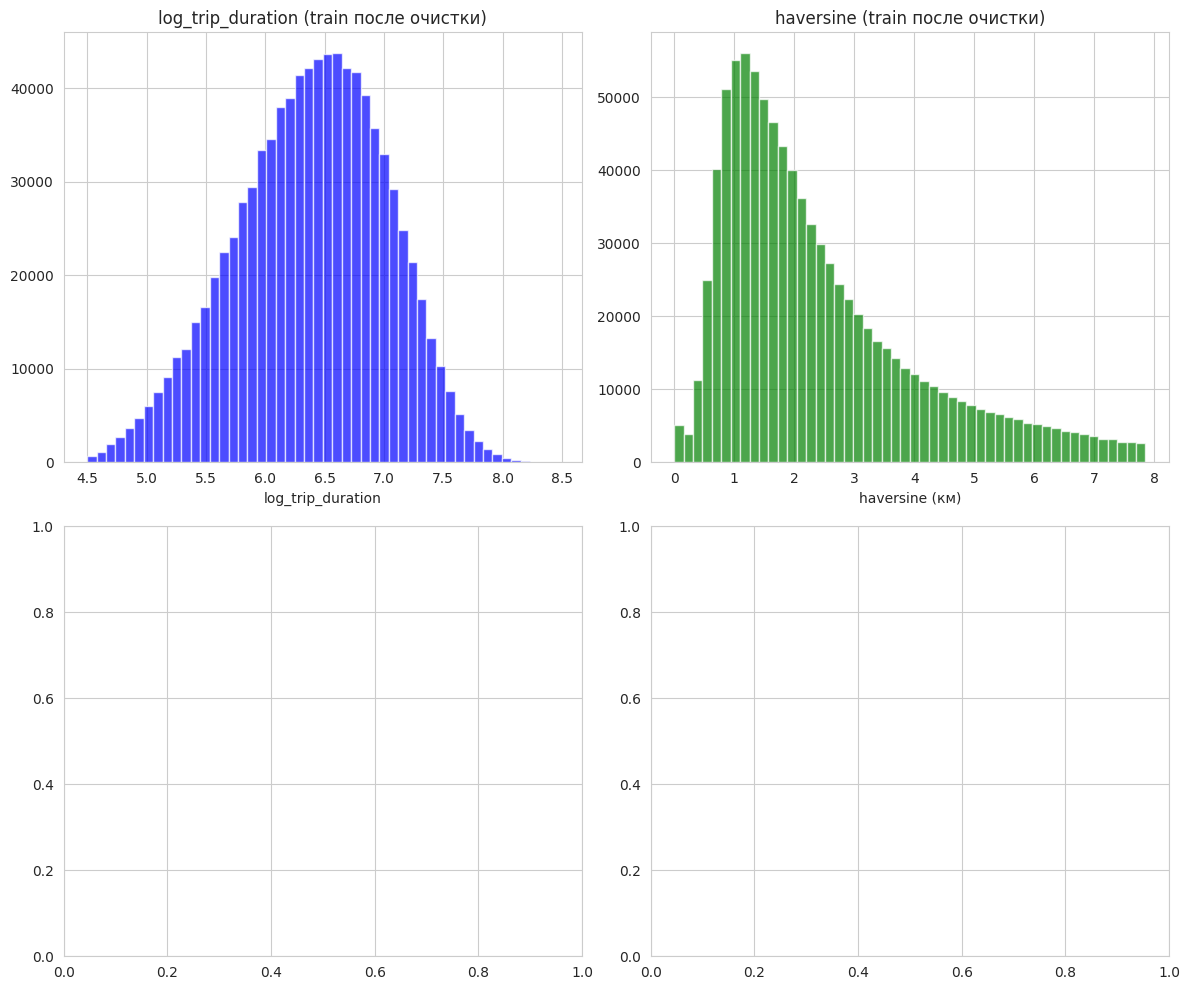

In [ ]:
#╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ

train_df, test_df = train_test_split(df, test_size=0.3, random_state=42)

print(f"Размер train до очистки: {len(train_df)}")
print(f"Размер test: {len(test_df)}")

# ---------- 3. Создание cell-признаков (одинаково для train и test) ----------
def get_cell(lon, lat, n_rows=10, n_cols=10):
    lon_min, lon_max = -74.05, -73.75
    lat_min, lat_max = 40.60, 40.90
    col = int((lon - lon_min) / (lon_max - lon_min) * n_cols)
    row = int((lat - lat_min) / (lat_max - lat_min) * n_rows)
    col = np.clip(col, 0, n_cols-1)
    row = np.clip(row, 0, n_rows-1)
    return row * n_cols + col

for df_part in (train_df, test_df):
    df_part['pickup_cell'] = df_part.apply(lambda r: get_cell(r['pickup_longitude'], r['pickup_latitude']), axis=1)
    df_part['dropoff_cell'] = df_part.apply(lambda r: get_cell(r['dropoff_longitude'], r['dropoff_latitude']), axis=1)

# ---------- 4. Определение признаков ----------
numerical_features = [
    'dayofyear', 'dayofweek', 'month', 'hour', 'passenger_count'
]

categorical_features = [
    'is_rush_hour', 'is_free_road',
    'rush_hour_start', 'rush_hour_end', 'free_road_start', 'free_road_end',
    'is_anomaly_period1', 'is_anomaly_period2',
    'pickup_cell', 'dropoff_cell',
    'vendor_id',
    'store_and_fwd_flag'
]

target = 'log_trip_duration'

# ---------- 5. Подготовка X, y для train (для получения остатков) ----------
X_train = train_df.drop(columns=[target, 'id', 'pickup_datetime'], errors='ignore')
y_train = train_df[target]

# ---------- 6. Обучение Ridge на ВСЕХ train данных (для вычисления остатков) ----------
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('ridge', Ridge(alpha=1.0))
])

pipeline.fit(X_train, y_train)
y_pred_train = pipeline.predict(X_train)
residuals_train = y_train - y_pred_train
train_df['residuals'] = residuals_train

# ---------- 7. Функция поиска выбросов по IQR ----------
def outliers_iqr(data, column, multiplier=1.5):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - multiplier * IQR
    upper = Q3 + multiplier * IQR
    return (data[column] < lower) | (data[column] > upper)

# ---------- 8. Гистограммы ДЛЯ TRAIN (до очистки) ----------
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0,0].hist(train_df[target], bins=50, alpha=0.7, color='blue')
axes[0,0].set_title(f'{target} (train до очистки)')
axes[0,0].set_xlabel(target)

# Для haversine ограничим визуализацию значениями <100 км
haversine_train_limited = train_df['haversine'][train_df['haversine'] < 100]
axes[0,1].hist(haversine_train_limited, bins=50, alpha=0.7, color='green')
axes[0,1].set_title('haversine (<100 км, train до очистки)')
axes[0,1].set_xlabel('haversine (км)')

axes[1,0].hist(train_df['residuals'], bins=50, alpha=0.7, color='red')
axes[1,0].set_title('Остатки Ridge (train до очистки)')
axes[1,0].set_xlabel('Остаток')

axes[1,1].hist(train_df['residuals'], bins=50, alpha=0.7, color='red')
axes[1,1].set_title('Остатки (обрезанные, train до очистки)')
axes[1,1].set_xlabel('Остаток')
axes[1,1].set_xlim(-3, 3)

plt.tight_layout()
plt.show()

# ---------- 9. Маска выбросов на TRAIN (логическое ИЛИ по трём критериям + ограничение haversine >= 100) ----------
outliers_log = outliers_iqr(train_df, target)
outliers_hav = outliers_iqr(train_df, 'haversine')
outliers_res = outliers_iqr(train_df, 'residuals')
outliers_hav_too_large = train_df['haversine'] >= 100   # явное ограничение

outliers_mask_train = outliers_log | outliers_hav | outliers_res | outliers_hav_too_large

print(f"Выбросы по {target} (train): {outliers_log.sum()}")
print(f"Выбросы по haversine (train): {outliers_hav.sum()}")
print(f"Выбросы по остаткам (train): {outliers_res.sum()}")
print(f"Выбросы по haversine >= 100 (train): {outliers_hav_too_large.sum()}")
print(f"Всего уникальных выбросов в train: {outliers_mask_train.sum()}")
print(f"Размер train до очистки: {len(train_df)}")
print(f"Размер train после очистки: {(~outliers_mask_train).sum()}")

# ---------- 10. Очистка TRAIN ----------
train_cleaned = train_df[~outliers_mask_train].copy()
train_cleaned.drop(columns=['residuals'], inplace=True)   # удаляем служебный столбец

# ---------- 11. Гистограммы ДЛЯ TRAIN (после очистки) ----------
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0,0].hist(train_cleaned[target], bins=50, alpha=0.7, color='blue')
axes[0,0].set_title(f'{target} (train после очистки)')
axes[0,0].set_xlabel(target)

axes[0,1].hist(train_cleaned['haversine'], bins=50, alpha=0.7, color='green')
axes[0,1].set_title('haversine (train после очистки)')
axes[0,1].set_xlabel('haversine (км)')

# В train_cleaned уже нет столбца 'residuals', поэтому построить гистограмму остатков после очистки не получится
# (остатки были удалены, их можно пересчитать, но это необязательно)

plt.tight_layout()
plt.show()

Сейчас у нас очень много категориальных признаков. В категориальных признаках могут содержаться редкие категории, обычно это плохо: модель сильно переобучается на таких примерах. Для каждого категориального признака объедините действительно редкие категории в одну, если такие имеются (т.е. если категории действительно редкие).


=== is_rush_hour ===
Топ-10 самых частых:
is_rush_hour
0    883863
1    574781
Name: count, dtype: int64

Топ-10 самых редких (не считая NaN):
is_rush_hour
0    883863
1    574781
Name: count, dtype: int64
Уникальных значений: 2
Категории, встречающиеся < 5 раз: 0 строк (0.00%)


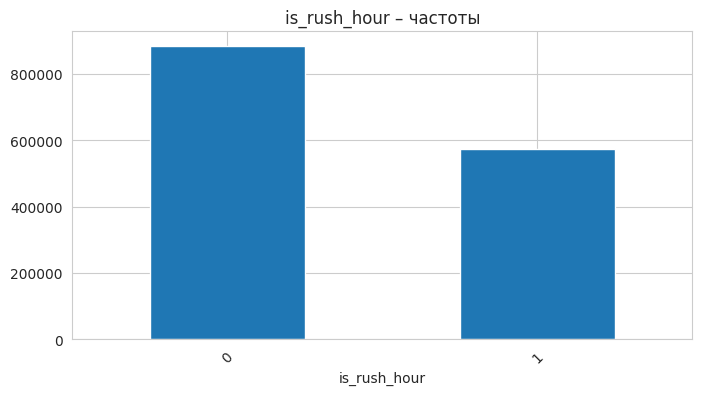


=== is_free_road ===
Топ-10 самых частых:
is_free_road
0    1253916
1     204728
Name: count, dtype: int64

Топ-10 самых редких (не считая NaN):
is_free_road
0    1253916
1     204728
Name: count, dtype: int64
Уникальных значений: 2
Категории, встречающиеся < 5 раз: 0 строк (0.00%)


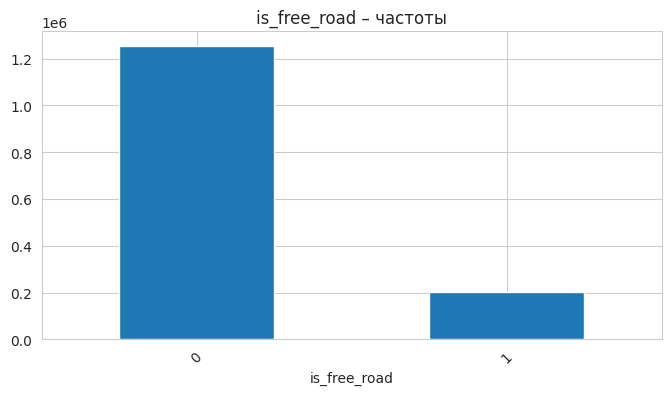


=== rush_hour_start ===
Топ-10 самых частых:
rush_hour_start
0    883863
1    574781
Name: count, dtype: int64

Топ-10 самых редких (не считая NaN):
rush_hour_start
0    883863
1    574781
Name: count, dtype: int64
Уникальных значений: 2
Категории, встречающиеся < 5 раз: 0 строк (0.00%)


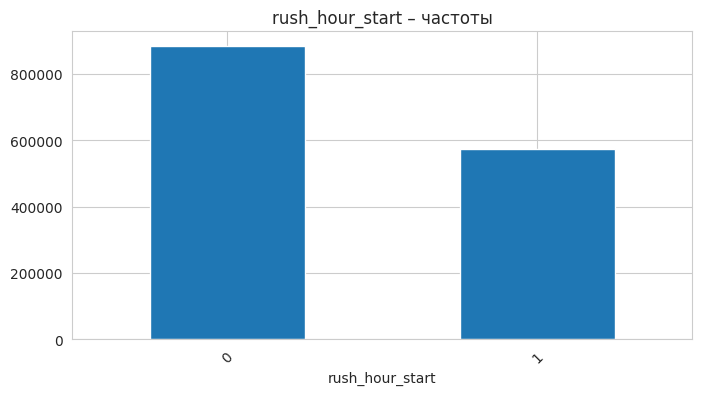


=== rush_hour_end ===
Топ-10 самых частых:
rush_hour_end
0    888639
1    570005
Name: count, dtype: int64

Топ-10 самых редких (не считая NaN):
rush_hour_end
0    888639
1    570005
Name: count, dtype: int64
Уникальных значений: 2
Категории, встречающиеся < 5 раз: 0 строк (0.00%)


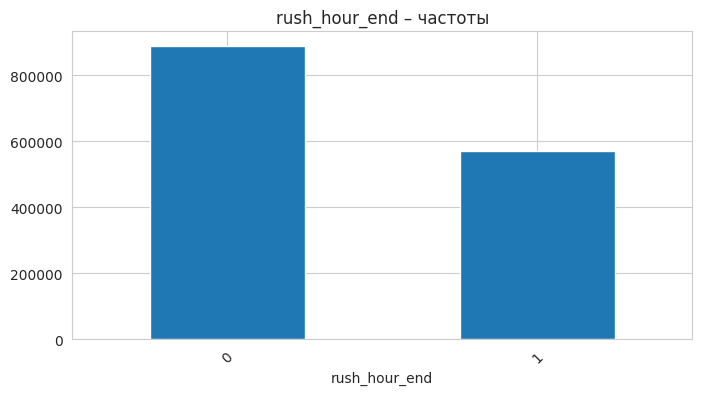


=== free_road_start ===
Топ-10 самых частых:
free_road_start
0    1253916
1     204728
Name: count, dtype: int64

Топ-10 самых редких (не считая NaN):
free_road_start
0    1253916
1     204728
Name: count, dtype: int64
Уникальных значений: 2
Категории, встречающиеся < 5 раз: 0 строк (0.00%)


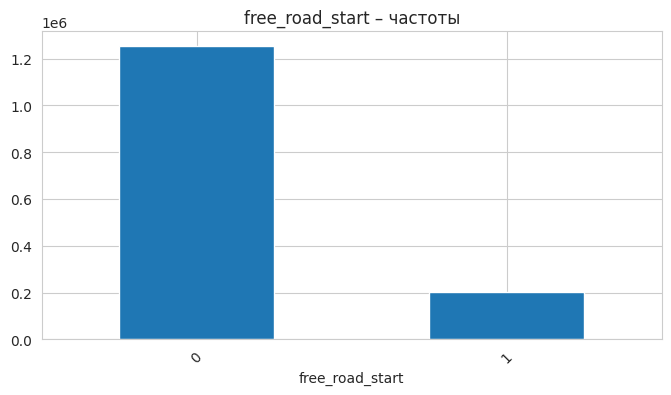


=== free_road_end ===
Топ-10 самых частых:
free_road_end
0    1246833
1     211811
Name: count, dtype: int64

Топ-10 самых редких (не считая NaN):
free_road_end
0    1246833
1     211811
Name: count, dtype: int64
Уникальных значений: 2
Категории, встречающиеся < 5 раз: 0 строк (0.00%)


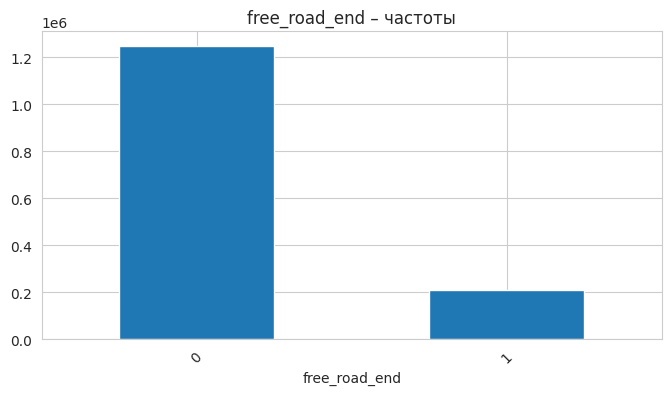


=== is_anomaly_period1 ===
Топ-10 самых частых:
is_anomaly_period1
0    1456996
1       1648
Name: count, dtype: int64

Топ-10 самых редких (не считая NaN):
is_anomaly_period1
0    1456996
1       1648
Name: count, dtype: int64
Уникальных значений: 2
Категории, встречающиеся < 5 раз: 0 строк (0.00%)


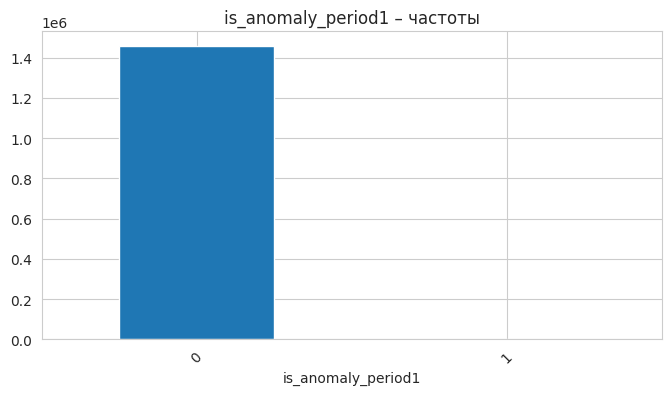


=== is_anomaly_period2 ===
Топ-10 самых частых:
is_anomaly_period2
0    1452272
1       6372
Name: count, dtype: int64

Топ-10 самых редких (не считая NaN):
is_anomaly_period2
0    1452272
1       6372
Name: count, dtype: int64
Уникальных значений: 2
Категории, встречающиеся < 5 раз: 0 строк (0.00%)


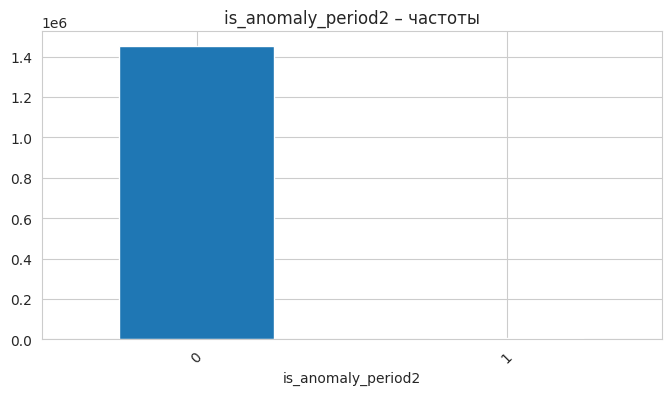


=== pickup_cell ===
Топ-10 самых частых:
pickup_cell
52    446972
41    259853
42    209032
53    102544
51     93253
62     86582
31     79565
63     53740
18     25457
55     21608
Name: count, dtype: int64

Топ-10 самых редких (не считая NaN):
pickup_cell
93    4
88    4
5     4
65    4
89    3
68    2
6     2
8     2
78    1
16    1
Name: count, dtype: int64
Уникальных значений: 100
Категории, встречающиеся < 5 раз: 27 строк (0.00%)


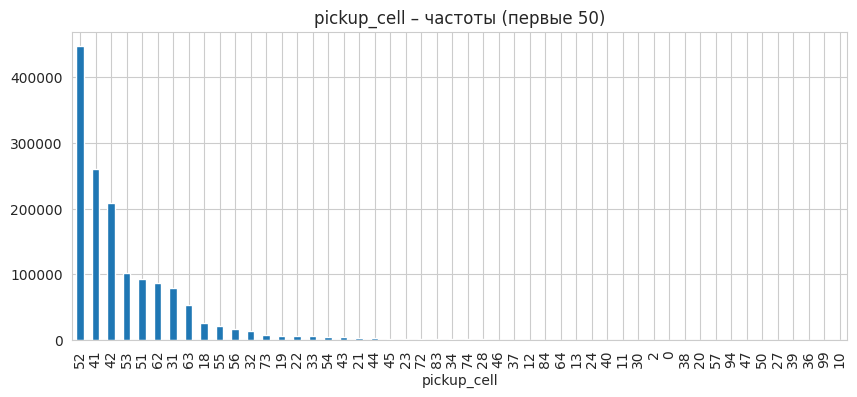


=== dropoff_cell ===
Топ-10 самых частых:
dropoff_cell
52    410229
41    223265
42    192075
53    103980
51     89643
62     88112
31     82517
63     73620
32     20476
73     16721
Name: count, dtype: int64

Топ-10 самых редких (не считая NaN):
dropoff_cell
8     32
17    29
88    27
65    26
78    22
89    20
93    19
5     16
81    14
71    12
Name: count, dtype: int64
Уникальных значений: 100
Категории, встречающиеся < 5 раз: 0 строк (0.00%)


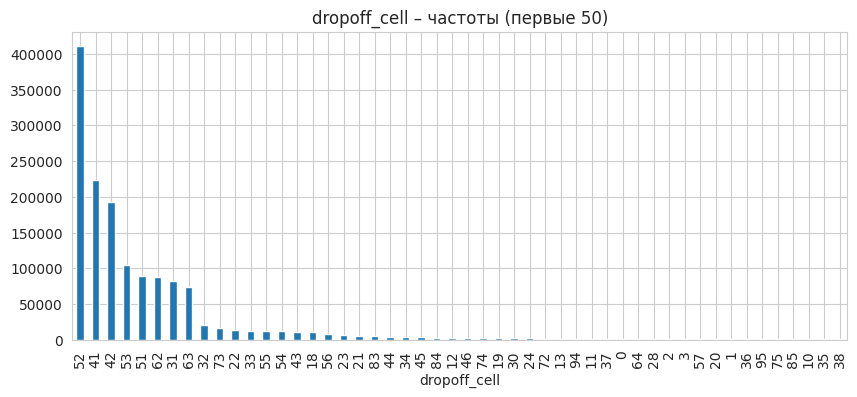


=== vendor_id ===
Топ-10 самых частых:
vendor_id
1    780302
0    678342
Name: count, dtype: int64

Топ-10 самых редких (не считая NaN):
vendor_id
1    780302
0    678342
Name: count, dtype: int64
Уникальных значений: 2
Категории, встречающиеся < 5 раз: 0 строк (0.00%)


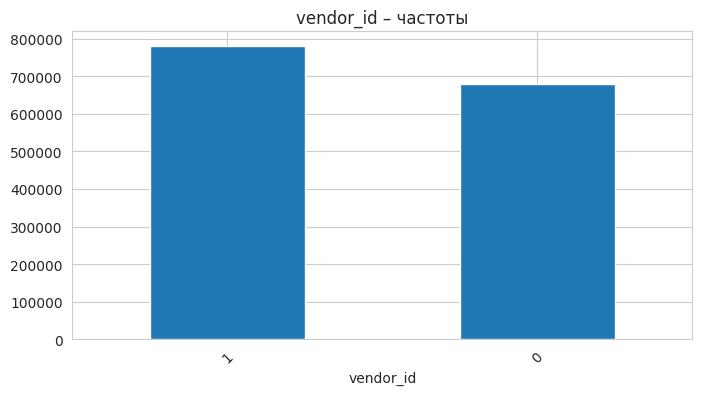


=== store_and_fwd_flag ===
Топ-10 самых частых:
store_and_fwd_flag
0    1450599
1       8045
Name: count, dtype: int64

Топ-10 самых редких (не считая NaN):
store_and_fwd_flag
0    1450599
1       8045
Name: count, dtype: int64
Уникальных значений: 2
Категории, встречающиеся < 5 раз: 0 строк (0.00%)


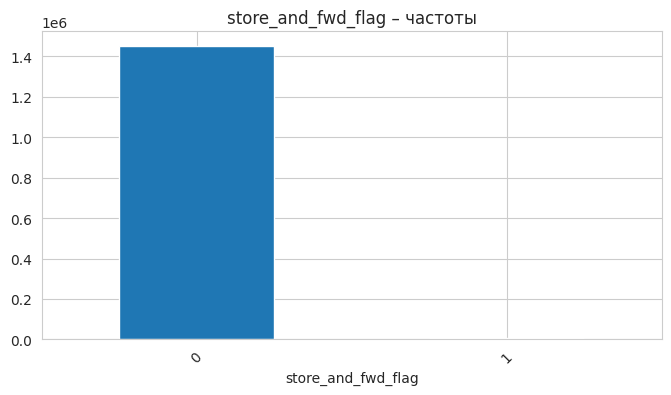

In [ ]:
#╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
for col in categorical_features:
    print(f"\n=== {col} ===")
    # Частотная таблица (value_counts) с нормализацией
    freq = df[col].value_counts()
    rel_freq = df[col].value_counts(normalize=True)

    # Первые 10 самых частых и последние 10 самых редких
    print("Топ-10 самых частых:")
    print(freq.head(10))
    print("\nТоп-10 самых редких (не считая NaN):")
    print(freq.tail(10))

    # Количество уникальных значений
    print(f"Уникальных значений: {df[col].nunique()}")

    # Процент строк, занимаемых редкими категориями (например, встречающимися менее 5 раз)
    rare_threshold = 5
    rare_mask = df[col].map(df[col].value_counts()) < rare_threshold
    rare_count = rare_mask.sum()
    rare_percent = rare_count / len(df) * 100
    print(f"Категории, встречающиеся < {rare_threshold} раз: {rare_count} строк ({rare_percent:.2f}%)")

    # Визуализация: гистограмма логарифмической шкалы (если много категорий)
    if df[col].nunique() > 20:
        plt.figure(figsize=(10,4))
        freq.head(50).plot(kind='bar')
        plt.title(f'{col} – частоты (первые 50)')
        plt.xticks(rotation=90)
        plt.show()
    else:
        plt.figure(figsize=(8,4))
        freq.plot(kind='bar')
        plt.title(f'{col} – частоты')
        plt.xticks(rotation=45)
        plt.show()

In [ ]:
def group_rare_cells(train_data, test_data, col, threshold):
    """
    Заменяет редкие значения (частота < threshold) в столбце col на 'rare'.
    train_data и test_data модифицируются на месте.
    """
    # Подсчёт частот в обучающей выборке
    freq = train_data[col].value_counts()
    rare_vals = freq[freq < threshold].index.tolist()

    # Замена в train
    train_data[col] = train_data[col].replace(rare_vals, 'rare')
    # Замена в test (используем тот же список редких значений)
    test_data[col] = test_data[col].replace(rare_vals, 'rare')

    print(f"{col}: заменено {len(rare_vals)} редких категорий на 'rare' (порог {threshold})")

# 3. Применяем к pickup_cell и dropoff_cell
group_rare_cells(train_df, test_df, 'pickup_cell', threshold=50000)
group_rare_cells(train_df, test_df, 'dropoff_cell', threshold=25000)

# 4. Проверка (по желанию) – сколько уникальных значений осталось
print(f"\nУникальных в 'pickup_cell' после замены (train): {train_df['pickup_cell'].nunique()}")
print(f"Уникальных в 'dropoff_cell' после замены (train): {train_df['dropoff_cell'].nunique()}")

pickup_cell: заменено 92 редких категорий на 'rare' (порог 50000)
dropoff_cell: заменено 92 редких категорий на 'rare' (порог 25000)

Уникальных в 'pickup_cell' после замены (train): 8
Уникальных в 'dropoff_cell' после замены (train): 9


Обучите модель на очищенных данных и посчитайте качество на тестовой выборке.

In [ ]:
target = 'log_trip_duration'

# Признаки (те же, что использовались ранее)
numerical_features = [
    'dayofyear', 'dayofweek', 'month', 'hour', 'passenger_count'
]

categorical_features = [
    'is_rush_hour', 'is_free_road',
    'rush_hour_start', 'rush_hour_end', 'free_road_start', 'free_road_end',
    'is_anomaly_period1', 'is_anomaly_period2',
    'pickup_cell', 'dropoff_cell',
    'vendor_id',
    'store_and_fwd_flag'
]

# Подготовка X и y для очищенного train
X_train_clean = train_cleaned.drop(columns=[target, 'id', 'pickup_datetime'], errors='ignore')
y_train_clean = train_cleaned[target]

# Подготовка X_test (из test_df, который не очищался)
X_test = test_df.drop(columns=[target, 'id', 'pickup_datetime'], errors='ignore')
y_test = test_df[target]

# Предобработка (такая же, как при вычислении остатков)
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

# Модель (Ridge с alpha по умолчанию, можно оптимизировать)
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('ridge', Ridge())
])

# Обучение на очищенном train
model.fit(X_train_clean, y_train_clean)

# Предсказание на test
y_pred = model.predict(X_test)

rmsle3 = rmsle(y_test, y_pred)
print(f"RMSLE на тестовой выборке: {rmsle3:.6f}")

RMSLE на тестовой выборке: 0.798733


**Задание 14 (1 балл)**. После OneHot-кодирования количество признаков в нашем датасете сильно возрастает. Посчитайте колиество признаков до и после кодирования категориальных признаков.

In [ ]:
#╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
numerical_features = ['dayofyear', 'dayofweek', 'month', 'hour', 'passenger_count']
categorical_features = [
    'is_rush_hour', 'is_free_road', 'rush_hour_start', 'rush_hour_end',
    'free_road_start', 'free_road_end', 'is_anomaly_period1', 'is_anomaly_period2',
    'pickup_cell', 'dropoff_cell', 'vendor_id', 'store_and_fwd_flag'
]

# Создаём препроцессор (как в пайплайне)
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

# Обучаем на очищенном тренировочном наборе (X_train_clean)
preprocessor.fit(X_train_clean)

# Количество признаков ДО кодирования = числовые признаки + категориальные признаки (как 1 фича каждый)
num_raw = len(numerical_features) + len(categorical_features)
print(f"Количество признаков до OneHot-кодирования: {num_raw}")

# Количество признаков ПОСЛЕ кодирования
# Получаем преобразованную матрицу (можно только получить количество столбцов без данных)
n_features_after = preprocessor.transform(X_train_clean[:1]).shape[1]
print(f"Количество признаков после OneHot-кодирования: {n_features_after}")

# Детализация: сколько бинарных фич дала каждая категориальная переменная
cat_encoder = preprocessor.named_transformers_['cat']
cat_feature_names = cat_encoder.get_feature_names_out(categorical_features)
print(f"Из них категориальных бинарных признаков: {len(cat_feature_names)}")

Количество признаков до OneHot-кодирования: 17
Количество признаков после OneHot-кодирования: 215
Из них категориальных бинарных признаков: 210


Попробуйте обучить не `Ridge`-, а `Lasso`-регрессию. Какой метод лучше?

In [ ]:
#╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
from sklearn.linear_model import Lasso
target = 'log_trip_duration'

# Подготовка X, y для очищенного train
X_train_clean = train_cleaned.drop(columns=[target, 'id', 'pickup_datetime'], errors='ignore')
y_train_clean = train_cleaned[target]

# Подготовка test
X_test = test_df.drop(columns=[target, 'id', 'pickup_datetime'], errors='ignore')
y_test = test_df[target]

# Предобработка (та же: StandardScaler + OneHotEncoder)
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

# Модель Lasso (alpha можно подобрать, для начала возьмём небольшое значение)
# Lasso чувствительна к масштабу признаков, но StandardScaler уже применён
lasso_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('lasso', Lasso())
])

# Обучение
lasso_model.fit(X_train_clean, y_train_clean)

# Предсказание на тесте
y_pred_lasso = lasso_model.predict(X_test)

# RMSLE (так как предсказываем логарифм, то просто RMSE)
rmsle_lasso = rmsle(y_test, y_pred_lasso)
print(f"RMSLE {rmsle_lasso:.6f}")

RMSLE на тесте (Lasso, alpha=0.001): 0.799413
